In [1]:
from IPython.display import display, clear_output
import os
import sourcedefender
import numpy as np
import torch
import sys
import argparse
import time
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from tqdm import tqdm
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split, dataset, Subset
import pandas as pd
import argparse
from mpl_toolkits.mplot3d import Axes3D
import gc
from datetime import datetime, timedelta

sys.path.append("../../../")
sys.path.append("../")
sys.path.append("./")

from lib.util import MHPI, UnitGaussianNormalizer
from lib.utilities3 import prepare_dataset, upscale_tensor, calculate_errors, check_if_from_ddp, adjust_state_dict, plot_log_loss, NonLocalMeansSmoothing, calculate_relative_errors
from lib.utiltools import loss_live_plot, GaussianRandomFieldGenerator, generate_batch_parameters, AutomaticWeightedLoss
from lib.DerivativeComputer import batchJacobian_AD_Dist
from lib.hellper import *
from lib.helper import LargeHydrologyDataset
from lib.helper import get_checkpoint_path
from lib.evaluation import evaluate_flood_metrics, inundation_extent_timeseries, plot_detection_skill_time, plot_inundation_extent_time, plot_ever_inundation_confusion

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f'Device: {device}\n')

# Dataset and case configuration
SAVED_MODEL_PATH = '../../../experiments/dam_break/saved_models'
# This creates a 'pointer' to the data on disk without filling up your RAM
case = 'dam_break'
operator_type = 'FNO'


Device: cuda:0



# Loading Dataset

In [2]:
eval_size = 150
batch_size = 8
T_Total = 49
DRY_THRESHOLD = 0.025 

T_in = 1
T_out = T_Total - T_in

Nx = 164 * 2
Ny = 164

In [5]:
# --- 1. Load Magnifier Model ---
train_size = 300

mode_mag = 'test_mag_residual_model5_Deeper_stage2_N1'
path_mag = '../../../experiments/saved_model/dam_break_model.pth'

checkpoint_mag = torch.load(path_mag, map_location=device, weights_only=False)

if 'stage1' in tag_mag:
    plot_log_loss(checkpoint_mag["loss_df_main"], mode=mode_mag + '_Global_Model' + f'  (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)
else:
    plot_log_loss(checkpoint_mag["loss_df_magnifier"], mode=mode_mag + '_Magnifier_Model' + f' (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)


loading dataset

In [9]:
config = checkpoint_mag.get('config_arg')
if isinstance(config, dict):
    experiment = config.get('experiment')
    if isinstance(experiment, dict):
        UQ_mode = experiment.get('UQ_mode', False)
    else:
        UQ_mode = False
else:
    UQ_mode = False



from pathlib import Path

data_dir = Path("../../../datasets/2_dam_break")

topo_path = data_dir / "dam_break_bed_topo.pt"
a_path    = data_dir / "dam_break_input.pt"
u_path    = data_dir / "dam_break_solution.pt"


if not UQ_mode:
    full_dataset = LargeHydrologyDataset(a_path, u_path, mask=True, 
                                        csv_path=os.path.join('../../../',  checkpoint_mag['config_arg']['data_mask']['csv_path']), 
                                        Lx=checkpoint_mag['config_arg']['data_mask']['L_x'], Ly=checkpoint_mag['config_arg']['data_mask']['L_y'])

    topo = torch.load(topo_path, map_location="cpu").to(device)  # ---- Static topo ---
    GLOBAL_TOPO_MIN = topo.min()
    GLOBAL_TOPO_MAX = topo.max()
    TOPO_RANGE = GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN + 1e-7

else:
    full_dataset = LargeHydrologyDataset(a_path, u_path, topo_path, mask=True, 
                                        csv_path=os.path.join('../../../',  checkpoint_mag['config_arg']['data_mask']['csv_path']), 
                                        Lx=checkpoint_mag['config_arg']['data_mask']['L_x'], Ly=checkpoint_mag['config_arg']['data_mask']['L_y'])

    GLOBAL_TOPO_MIN = full_dataset.b.min()
    GLOBAL_TOPO_MAX = full_dataset.b.max()
    TOPO_RANGE = GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN + 1e-7
    GLOBAL_TOPO_MEAN = full_dataset.b.mean(dim=(0, 1, 2))
    GLOBAL_TOPO_STD  = full_dataset.b.std(dim=(0, 1, 2)) + 1e-6


# 2. Split with a fixed generator for reproducibility
n = len(full_dataset)

# Make deterministic indices
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n, generator=g).tolist()
test_idx  = perm[train_size + eval_size:]
test_dataset = Subset(full_dataset, test_idx)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Loading Trained Models

In [10]:
from models.fno3d_encoder import FNO3d
from models.magnifier5 import FiLMLightMagnifier as magnifier

# --- 1. Load Global Model ---
model_global = FNO3d(
    T_in=T_in, T_out=T_out,
    modes_x=checkpoint_mag['config']['Mode1_G'], 
    modes_y=checkpoint_mag['config']['Mode2_G'], 
    modes_t=checkpoint_mag['config']['Mode3_G'],
    width=checkpoint_mag['config']['width_FNO'],
    
    encoder_kernel_size_x=82,
    encoder_kernel_size_y=41,
    encoder_num_layers=4
)

is_DDP_glb = check_if_from_ddp(checkpoint_mag)
  
if is_DDP_glb:   
    adjusted_state_dict = adjust_state_dict(checkpoint_mag['model_state_dict'], model_global)
    model_global.load_state_dict(adjusted_state_dict)
else:
    model_global.load_state_dict(checkpoint_mag['model_state_dict'])

model_global = model_global.to(device)

plot_log_loss(checkpoint_mag["loss_df_main"], mode=mode_mag + '_Global_Model' + f'  (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)

In [11]:
# --- 2. Load Magnifier Model ---

tag_mag_stage2 = 'test_mag_residual_model5_Deeper_stage2_N1'
path_mag_2 = '../../../experiments/saved_model/dam_break_best_model.pth'
mode_mag = 'test_mag_residual_model5_Deeper_stage2_N1'

checkpoint_mag = torch.load(path_mag_2, map_location=device, weights_only=False)


if 'stage1' in mode_mag:
    plot_log_loss(checkpoint_mag["loss_df_main"], mode=mode_mag + '_Global_Model' + f'  (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)
else:
    plot_log_loss(checkpoint_mag["loss_df_magnifier"], mode=mode_mag + '_Magnifier_Model' + f' (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)



model_magnifier = magnifier(width=64).to(device)

is_DDP_mag = check_if_from_ddp(checkpoint_mag)

state_dict_mag = checkpoint_mag['magnifier_state_dict'] 

if is_DDP_mag:   
    state_dict_mag = adjust_state_dict(state_dict_mag, model_magnifier)

model_magnifier.load_state_dict(state_dict_mag)

<All keys matched successfully>

# Generate coarse-resolution depth predictions using the trained global model.

In [19]:
import time
import torch
from tqdm import tqdm
from lib.helper import coarsen_spatial_tensor

model_global.eval()

# ---- user control ----
MAX_SAMPLES = 50   # <- set this to how many samples you want

# ---- load topo once ----


# ---- CPU buffers ----
forcing_all = torch.empty(0, device="cpu")
u0_all      = torch.empty(0, device="cpu")
u_true_all  = torch.empty(0, device="cpu")
u_pred_coarse_all  = torch.empty(0, device="cpu")
bed_topo_all = torch.empty(0, device="cpu")

t_start = time.time()
num_collected = 0

with torch.no_grad():
    for _, batch_data in tqdm(enumerate(test_loader, 1), total=len(test_loader),
                              desc="Processing batches"):

        batch_data = [item.to(device, non_blocking=True) for item in batch_data]
        batch_forcing = batch_data[0][..., ::2]
        batch_sol     = batch_data[1][..., ::2]

        # batch_u0    = torch.ones_like(batch_sol[..., :T_in])
        batch_u0    = batch_sol[..., :T_in]

        batch_u_out = batch_sol[..., T_in:]

        bs = batch_u0.shape[0]

        # ---- trim batch if it would exceed MAX_SAMPLES ----
        remaining = MAX_SAMPLES - num_collected
        if remaining <= 0:
            break
        if bs > remaining:
            batch_forcing = batch_forcing[:remaining]
            batch_u0      = batch_u0[:remaining]
            batch_u_out   = batch_u_out[:remaining]
            bs = remaining

        if UQ_mode:
            batch_topo = batch_data[2]          # shape should be [bs, nx, ny] (or [bs, nx, ny, 1] etc.)
        else:
            batch_topo = topo.expand(bs, -1, -1)


        U_pred_batch = model_global(batch_forcing, batch_u0, batch_topo)
        U_pred_batch[U_pred_batch < DRY_THRESHOLD] = 0
        # ---- move to CPU ----
        forcing_all = torch.cat((forcing_all, batch_forcing.cpu()), dim=0)
        u0_all      = torch.cat((u0_all, batch_u0.cpu()), dim=0)
        u_true_all  = torch.cat((u_true_all, batch_u_out.cpu()), dim=0)
        u_pred_coarse_all  = torch.cat((u_pred_coarse_all, U_pred_batch.cpu()), dim=0)
        bed_topo_all = torch.cat((bed_topo_all, batch_topo.cpu()), dim=0)
        num_collected += bs

        del batch_forcing, batch_sol, batch_u0, batch_u_out, batch_topo, U_pred_batch
        
u_pred_coarse_all[u_pred_coarse_all < DRY_THRESHOLD] = 0.0
u_true_all[u_true_all < DRY_THRESHOLD] = 0.0

t_end = time.time()
print(
    f"Processed {num_collected} samples in {t_end - t_start:.2f}s "
    f"({(t_end - t_start)/max(num_collected,1):.3f} s/sample)"
)

u_true_all_coarse = coarsen_spatial_tensor(u_true_all, N=4,  mode='area')


Processing batches:  10%|█         | 7/69 [00:08<01:16,  1.24s/it]


Processed 50 samples in 9.56s (0.191 s/sample)


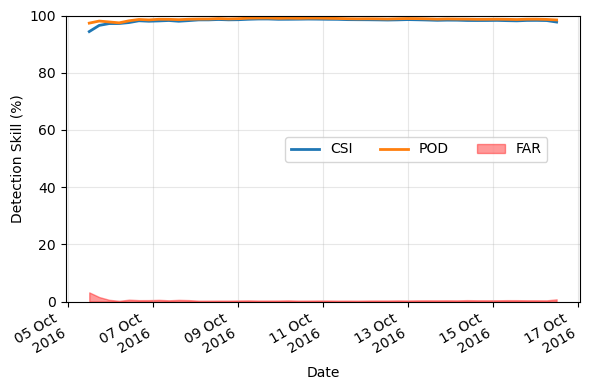

In [20]:
metrics_coarse = evaluate_flood_metrics(
    Depth_True=u_true_all_coarse,
    Depth_Pred=u_pred_coarse_all,
    wet_threshold=0.025,
    peak_percent=0.025
)


fig, ax = plot_detection_skill_time(
    metrics_coarse['dynamic'],
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


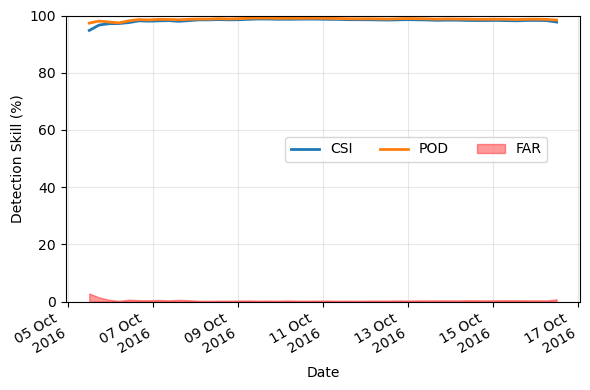

In [21]:
metrics_coarse['static']

{'relRMSE_mean': 0.012989053502678871,
 'relRMSE_std': 0.004386045970022678,
 'NSE_mean': 0.9999831318855286,
 'NSE_std': 1.0311399819329381e-05,
 'relRMSE_shallow_mean': 0.3873825967311859,
 'relRMSE_shallow_std': 0.07597699761390686,
 'NSE_shallow_mean': 0.9955270290374756,
 'NSE_shallow_std': 0.001541710807941854,
 'relRMSE_deep_mean': 0.0031722248531877995,
 'relRMSE_deep_std': 0.0009632881847210228,
 'NSE_deep_mean': 0.9999666810035706,
 'NSE_deep_std': 2.3508113372372463e-05,
 'POD_mean': 0.9882203936576843,
 'POD_std': 0.0020574769005179405,
 'FAR_mean': 0.004019927233457565,
 'FAR_std': 0.002796816872432828,
 'CSI_mean': 0.9842894077301025,
 'CSI_std': 0.002583105582743883,
 'relPeakValErr_mean': 0.0002440419775666669,
 'relPeakValErr_std': 0.00042194745037704706,
 'relPeakTimeErr1_mean': 0.0,
 'relPeakTimeErr1_std': 0.0,
 'relPeakTimeErr2_mean': 0.0,
 'relPeakTimeErr2_std': 0.0}

In [34]:
metrics_coarse['static']

{'relRMSE_mean': 0.013109139166772366,
 'relRMSE_std': 0.004383689723908901,
 'NSE_mean': 0.9999828338623047,
 'NSE_std': 1.0349075637350325e-05,
 'relRMSE_shallow_mean': 0.38465794920921326,
 'relRMSE_shallow_std': 0.07260545343160629,
 'NSE_shallow_mean': 0.9955920577049255,
 'NSE_shallow_std': 0.001472101779654622,
 'relRMSE_deep_mean': 0.0032486917916685343,
 'relRMSE_deep_std': 0.000992139452137053,
 'NSE_deep_mean': 0.9999648928642273,
 'NSE_deep_std': 2.473426502547227e-05,
 'POD_mean': 0.9880795478820801,
 'POD_std': 0.002074246760457754,
 'FAR_mean': 0.0039056106470525265,
 'FAR_std': 0.0027646070811897516,
 'CSI_mean': 0.9842612743377686,
 'CSI_std': 0.002583702327683568,
 'relPeakValErr_mean': 0.00044313512626104057,
 'relPeakValErr_std': 0.00040843113674782217,
 'relPeakTimeErr1_mean': 0.0,
 'relPeakTimeErr1_std': 0.0,
 'relPeakTimeErr2_mean': 0.0,
 'relPeakTimeErr2_std': 0.0}

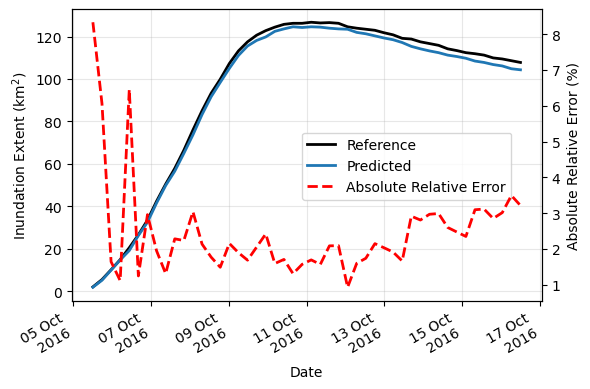

In [22]:
idx = 0
wet_threshold = 0.02

inundation_extent_coarse_pred = inundation_extent_timeseries(
    depth=u_pred_coarse_all,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


inundation_extent_coarse_true = inundation_extent_timeseries(
    depth=u_true_all_coarse,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


fig, ax1, ax2 = plot_inundation_extent_time(
    inundation_extent_coarse_true,
    inundation_extent_coarse_pred,
    idx=10,
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


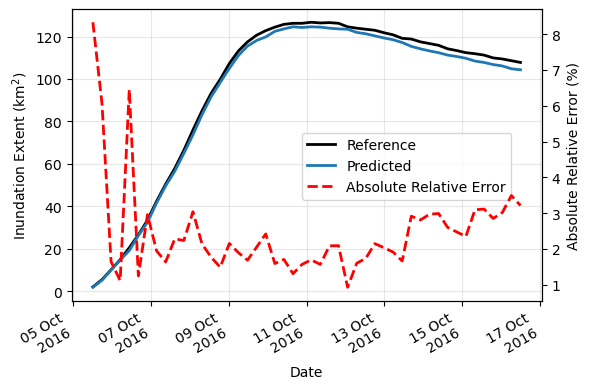

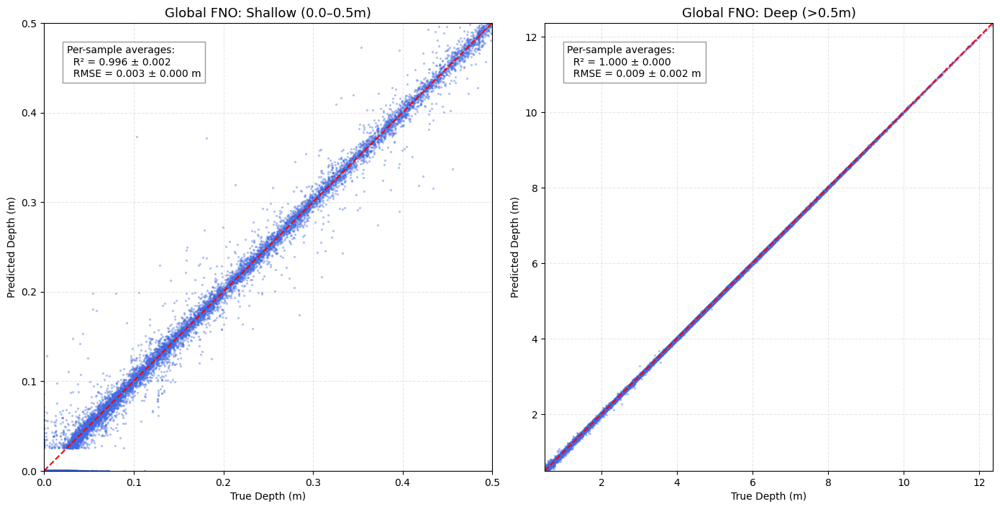

In [23]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# ─── Data Setup: Focus on Coarse Row Only ────────────────────────────────────
# u_true_all_coarse: Ground Truth after 'area' coarsening
# u_pred_coarse_all: Raw FNO output before upscaling
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# Dataset list reduced to just the Coarse Global Model
datasets = [(u_true_c, u_pred_c, "Global FNO (Coarse)")]

# Define depth ranges (m)
depth_ranges = [
    (0.0, 0.5, "Shallow (0.0–0.5m)"),
    (0.5, u_true_c.max(), "Deep (>0.5m)")
]

# Create 1 row x 2 cols plot
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Since there's only one row, axes will be a 1D array
for col_idx, (dmin, dmax, range_title) in enumerate(depth_ranges):
    ax = axes[col_idx]
    
    r2_list, rmse_list = [], []
    scatter_x, scatter_y = [], []
    
    for i in range(u_true_c.shape[0]):
        true_flat = u_true_c[i].ravel()
        pred_flat = u_pred_c[i].ravel()
        
        # Apply depth mask
        mask = (true_flat >= dmin) & (true_flat < dmax)
        if np.sum(mask) < 50: continue
            
        x_s, y_s = true_flat[mask], pred_flat[mask]
        
        r2_list.append(r2_score(x_s, y_s))
        rmse_list.append(np.sqrt(mean_squared_error(x_s, y_s)))
        
        # Subsampling for performance
        if len(x_s) > 5000:
            sel = np.random.choice(len(x_s), 5000, replace=False)
            scatter_x.extend(x_s[sel]); scatter_y.extend(y_s[sel])
        else:
            scatter_x.extend(x_s); scatter_y.extend(y_s)
    
    # Plotting
    ax.scatter(scatter_x, scatter_y, s=2, alpha=0.3, color='royalblue', rasterized=True)
    limit_max = dmax if np.isfinite(dmax) else max(scatter_x)
    ax.plot([dmin, limit_max], [dmin, limit_max], 'r--', lw=1.5, label='Ideal')
    
    ax.set_xlim(dmin, limit_max); ax.set_ylim(dmin, limit_max)
    ax.set_aspect('equal')
    
    metrics_text = (
        f"Per-sample averages:\n"
        f"  R² = {np.mean(r2_list):.3f} ± {np.std(r2_list):.3f}\n"
        f"  RMSE = {np.mean(rmse_list):.3f} ± {np.std(rmse_list):.3f} m"
    )
    ax.text(0.05, 0.95, metrics_text, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))
    
    ax.set_title(f"Global FNO: {range_title}", fontsize=13)
    ax.set_xlabel("True Depth (m)"); ax.set_ylabel("Predicted Depth (m)")
    ax.grid(True, ls='--', alpha=0.3)

plt.tight_layout()
plt.show()

Plot inundation confusion

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Ever-inundation confusion (sample=20, th=0.01 m)'}, xlabel='x (km)', ylabel='y (km)'>)

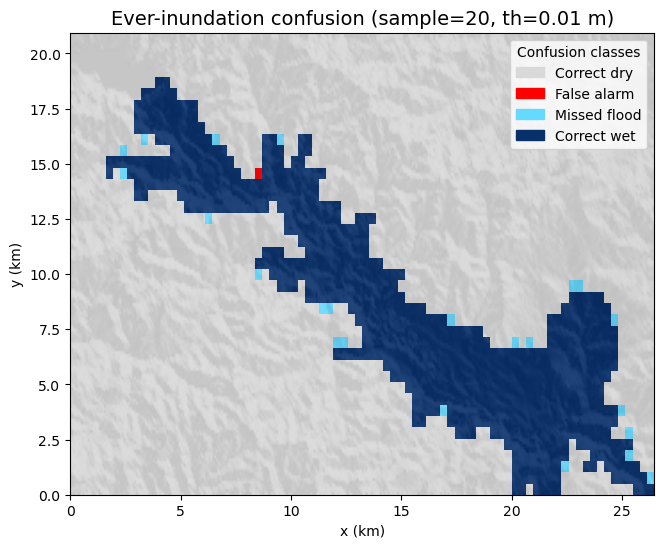

In [24]:
Lx=checkpoint_mag['config_arg']['data_mask']['L_x']
Ly=checkpoint_mag['config_arg']['data_mask']['L_y']
extent = [0, Lx, 0, Ly]

# extent = [0, 248417.934 - 201527.934, 0, 3922540.192 - 3898940.192]
plot_ever_inundation_confusion(
    u_true=u_true_all_coarse, 
    u_pred=u_pred_coarse_all,
    bed=bed_topo_all,              # <-- pass your bed tensor here
    sample_idx=20,
    inund_th=0.01,
    extent=extent,
    hill_vert_exag=3.0,            # tweak for stronger relief
    overlay_alpha=0.9
)



In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import LightSource
from IPython.display import HTML
from datetime import datetime, timedelta

# ==========================================
# 1) Data Selection & Error Calculation (Coarse Only)
# ==========================================
sample_idx = 20

u_true_c = u_true_all_coarse[..., ::2][sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[..., ::2][sample_idx].detach().cpu().numpy()
u_err_c  = np.abs(u_true_c - u_pred_c)

num_frames = u_true_c.shape[-1]

# ==========================================
# 2) Time + extent
# ==========================================
start_date = datetime(2016, 10, 5, 12, 0, 0)
time_step_seconds = 3600
time_dates = [start_date + timedelta(seconds=i * time_step_seconds) for i in range(num_frames)]

vmin, vmax = 0.0, 0.8 * u_true_c.max()
err_vmin, err_vmax = 0.0, 0.2

Lx = checkpoint_mag['config_arg']['data_mask']['L_x']
Ly = checkpoint_mag['config_arg']['data_mask']['L_y']
extent = [0, Lx, 0, Ly]

# ==========================================
# 3) Styling like your "first row" example
# ==========================================
min_depth_threshold = 0.025
cmp = "winter"
bed_cmap = "gist_yarg"

def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# 4) Hillshade bed background (same as first row script)
# ==========================================
# Use your bed tensor here (NOT water). Example: bed_topo_all
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
# if bed is [ny, nx], transpose it once here
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# Use physical cell size if you want, but keep it identical style to your example:
dx = 1.0
dy = 1.0
ls = LightSource(azdeg=315, altdeg=45)
hill = ls.hillshade(bed_sample, vert_exag=2.5, dx=dx, dy=dy)  # [0..1]

# ==========================================
# 5) Figure Setup: 1 Row x 3 Columns (first-row look)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
titles = ["True (Coarse)", "Pred (Coarse)", "Abs Error (Coarse)"]
ims = [None] * 3
bed_imgs = []

for c, ax in enumerate(axes):
    # 1) Hillshade background (static)
    bed_img = ax.imshow(
        hill.T, extent=extent, origin="lower",
        cmap=bed_cmap, vmin=0, vmax=1,
        alpha=1.0, zorder=1
    )
    bed_imgs.append(bed_img)

    # 2) Foreground layer (dynamic)
    if c == 0:
        ims[c] = ax.imshow(
            mask_dry(u_true_c[:, :, 0]).T, extent=extent, origin="lower",
            cmap=cmp, vmin=vmin, vmax=vmax,
            alpha=0.85, zorder=2
        )
    elif c == 1:
        ims[c] = ax.imshow(
            mask_dry(u_pred_c[:, :, 0]).T, extent=extent, origin="lower",
            cmap=cmp, vmin=vmin, vmax=vmax,
            alpha=0.85, zorder=2
        )
    else:
        ims[c] = ax.imshow(
            u_err_c[:, :, 0].T, extent=extent, origin="lower",
            cmap="magma", vmin=err_vmin, vmax=err_vmax,
            alpha=0.7, zorder=2
        )

    ax.set_title(titles[c], fontsize=14)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.set_xlabel("Easting (m)")

axes[0].set_ylabel("Northing (m)")

# Colorbars
cbar_ax1 = fig.add_axes([0.15, 0.08, 0.35, 0.03])
fig.colorbar(ims[0], cax=cbar_ax1, label="Water Depth (m)", orientation="horizontal")

cbar_ax2 = fig.add_axes([0.65, 0.08, 0.20, 0.03])
fig.colorbar(ims[2], cax=cbar_ax2, label="Abs Error (m)", orientation="horizontal")

plt.subplots_adjust(bottom=0.22, wspace=0.15)

# ==========================================
# 6) Update Function
# ==========================================
def update(f_idx):
    current_dt = time_dates[f_idx]
    fig.suptitle(
        f"Global FNO Dynamics: Sample {sample_idx}\nTime: {current_dt.strftime('%Y-%m-%d %H:%M')}",
        fontsize=16, fontweight="bold"
    )

    ims[0].set_data(mask_dry(u_true_c[:, :, f_idx]).T)
    ims[1].set_data(mask_dry(u_pred_c[:, :, f_idx]).T)
    ims[2].set_data(u_err_c[:, :, f_idx].T)

    return ims

# ==========================================
# 7) Animation
# ==========================================
ani = animation.FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())


# Apply the trained Magnifier for topography-aware upscaling.

In [25]:
from lib.helper import prepare_patch_input, BathtubReconstructor
import torch
import torch.nn.functional as F
from tqdm import tqdm

model_magnifier.eval()

# ---- Configuration from Checkpoints ----
N = checkpoint_mag['config']['N_window']       # e.g., 5
f = checkpoint_mag['config']['f_upscale']      # e.g., 10
T_out = checkpoint_mag['config']['T_out']

# Global dimensions
num_samples, mx, my, _ = u_pred_coarse_all.shape
nx_fine, ny_fine = mx * f, my * f

# ---- Initialize Reconstructor for Inference ----
reconstructor = BathtubReconstructor(f=f, max_iters=20).to(device)

# ---- Buffers ----
u_upscaled_acc = torch.zeros((num_samples, nx_fine, ny_fine, T_out), device="cpu")
u_upscaled_cnt = torch.zeros((num_samples, nx_fine, ny_fine, T_out), device="cpu")

# ---- Global Normalization Constants ----
GLOBAL_TOPO_MIN = bed_topo_all.min()
GLOBAL_TOPO_MAX = bed_topo_all.max()
TOPO_RANGE = (GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN) + 1e-7

# ---- 1. Generate Global Bathtub Reconstruction ----
print("Generating Global Bathtub Baseline...")
with torch.no_grad():
    u_bt_global = reconstructor(u_pred_coarse_all.to(device), bed_topo_all.to(device))

# ---- 2. Padding Alignment ----
pad_size = N // 2

u_pad = F.pad(
    u_pred_coarse_all.permute(0, 3, 1, 2),
    (pad_size, pad_size, pad_size, pad_size),
    mode="replicate",
).permute(0, 2, 3, 1).to(device)

pad_size_f = pad_size * f

u_bt_pad = F.pad(
    u_bt_global.permute(0, 3, 1, 2),
    (pad_size_f, pad_size_f, pad_size_f, pad_size_f),
    mode="replicate",
).permute(0, 2, 3, 1).to(device)

topo_norm = (bed_topo_all.to(device) - GLOBAL_TOPO_MIN) / TOPO_RANGE
topo_pad = F.pad(
    topo_norm,
    (pad_size_f, pad_size_f, pad_size_f, pad_size_f),
    mode="replicate",
).to(device)

print(f"Starting Aligned Magnifier Upscaling for {num_samples} samples...")

center_start = (N // 2) * f
center_end = center_start + f

with torch.no_grad():
    step = 1
    for i_s in tqdm(range(0, mx, step), desc="Spatial X"):
        for j_s in range(0, my, step):

            # ---------------------------------------------------------
            # Gate ONLY by the CENTER coarse cell (the one we stitch)
            # ---------------------------------------------------------
            ic = i_s + (N // 2)
            jc = j_s + (N // 2)

            center_coarse_ts = u_pad[:, ic, jc, :]  # [nb, nt]
            center_is_wet = (center_coarse_ts.max(dim=-1).values >= DRY_THRESHOLD)  # [nb]

            # Fine indices for the stitched fxf block
            x_start, x_end = i_s * f, i_s * f + f
            y_start, y_end = j_s * f, j_s * f + f

            # ---------------------------------------------------------
            # If center is dry -> DO NOT use magnifier, FORCE ZERO
            # (acc stays 0; count increments so average is 0)
            # ---------------------------------------------------------

            if not center_is_wet.any():
                u_upscaled_cnt[:, x_start:x_end, y_start:y_end, :] += 1.0
                continue

            # move indices to CPU because u_upscaled_acc/cnt are on CPU
            wet_idx = torch.where(center_is_wet)[0].to("cpu")
            dry_idx = torch.where(~center_is_wet)[0].to("cpu")

            # Prepare patch input on GPU, then slice using GPU indices
            wet_idx_gpu = wet_idx.to(device)

            p_in = prepare_patch_input(u_pad, topo_pad, i_s, j_s, N, f, device, u_bathtub=u_bt_pad)
            p_in_wet = p_in[wet_idx_gpu]

            p_residual = model_magnifier(p_in_wet).squeeze(1)

            p_bt_patch = u_bt_pad[
                wet_idx_gpu,
                i_s*f : i_s*f + N*f,
                j_s*f : j_s*f + N*f,
                :
            ]

            p_out = p_bt_patch + p_residual
            p_out[p_out < DRY_THRESHOLD] = 0.0

            p_center = p_out[:, center_start:center_end, center_start:center_end, :].cpu()

            # CPU indexing with CPU indices ✅
            u_upscaled_acc[wet_idx, x_start:x_end, y_start:y_end, :] += p_center
            u_upscaled_cnt[wet_idx, x_start:x_end, y_start:y_end, :] += 1.0

            # dry -> force zero (count only)
            if dry_idx.numel() > 0:
                u_upscaled_cnt[dry_idx, x_start:x_end, y_start:y_end, :] += 1.0



# ---- Final Averaging ----
mask = u_upscaled_cnt > 0
u_upscaled_final = torch.zeros_like(u_upscaled_acc)
u_upscaled_final[mask] = u_upscaled_acc[mask] / u_upscaled_cnt[mask]

print(f"Upscaling Complete. Final Shape: {u_upscaled_final.shape}")


Generating Global Bathtub Baseline...
Starting Aligned Magnifier Upscaling for 50 samples...


Spatial X: 100%|██████████| 82/82 [00:05<00:00, 13.87it/s]


Upscaling Complete. Final Shape: torch.Size([50, 328, 164, 48])


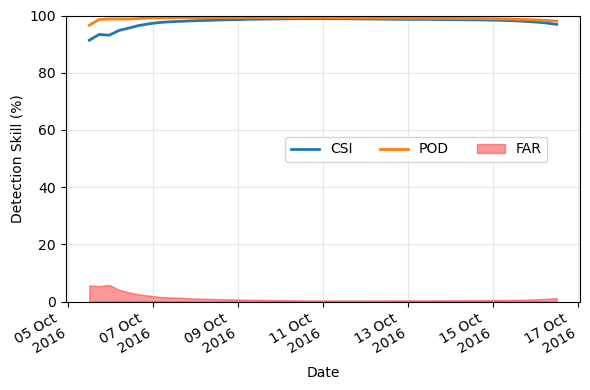

In [26]:
metrics_fine = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=u_upscaled_final,
    wet_threshold=0.1,
    peak_percent=0.1
)


fig, ax = plot_detection_skill_time(
    metrics_fine['dynamic'],
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


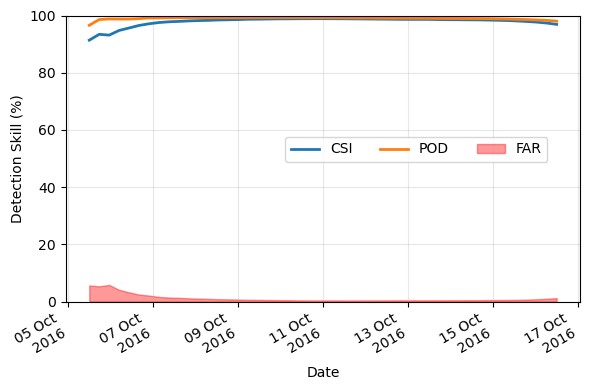

In [27]:
metrics_fine['static']

{'relRMSE_mean': 0.0374695286154747,
 'relRMSE_std': 0.01020184438675642,
 'NSE_mean': 0.9998815059661865,
 'NSE_std': 5.359871283872053e-05,
 'relRMSE_shallow_mean': 2.1503047943115234,
 'relRMSE_shallow_std': 0.30165770649909973,
 'NSE_shallow_mean': 0.9412616491317749,
 'NSE_shallow_std': 0.014737355522811413,
 'relRMSE_deep_mean': 0.009255494922399521,
 'relRMSE_deep_std': 0.0019218595698475838,
 'NSE_deep_mean': 0.9997397065162659,
 'NSE_deep_std': 0.00011534225632203743,
 'POD_mean': 0.9904573559761047,
 'POD_std': 0.0012807416496798396,
 'FAR_mean': 0.006062017288058996,
 'FAR_std': 0.0013623540289700031,
 'CSI_mean': 0.9845120906829834,
 'CSI_std': 0.0023136402014642954,
 'relPeakValErr_mean': -0.00032074772752821445,
 'relPeakValErr_std': 0.0004456245223991573,
 'relPeakTimeErr1_mean': 0.0,
 'relPeakTimeErr1_std': 0.0,
 'relPeakTimeErr2_mean': 0.0,
 'relPeakTimeErr2_std': 0.0}

{'relRMSE_mean': 0.03747902065515518,
 'relRMSE_std': 0.010163526982069016,
 'NSE_mean': 0.9998814463615417,
 'NSE_std': 5.329876876203343e-05,
 'relRMSE_shallow_mean': 2.140378475189209,
 'relRMSE_shallow_std': 0.29622405767440796,
 'NSE_shallow_mean': 0.9418248534202576,
 'NSE_shallow_std': 0.014299619011580944,
 'relRMSE_deep_mean': 0.009288373403251171,
 'relRMSE_deep_std': 0.0019232297781854868,
 'NSE_deep_mean': 0.9997378587722778,
 'NSE_deep_std': 0.0001156698344857432,
 'POD_mean': 0.9903782606124878,
 'POD_std': 0.0012802326818928123,
 'FAR_mean': 0.005966332741081715,
 'FAR_std': 0.0013391543179750443,
 'CSI_mean': 0.9845277667045593,
 'CSI_std': 0.0022946123499423265,
 'relPeakValErr_mean': -0.0001215065858559683,
 'relPeakValErr_std': 0.0004701788420788944,
 'relPeakTimeErr1_mean': 0.0,
 'relPeakTimeErr1_std': 0.0,
 'relPeakTimeErr2_mean': 0.0,
 'relPeakTimeErr2_std': 0.0}

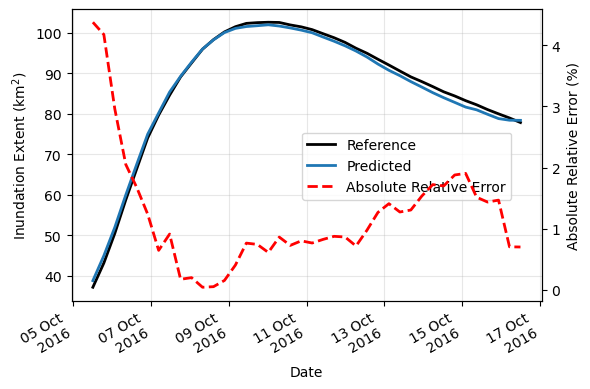

In [28]:
idx = 20
wet_threshold = 0.025

inundation_extent_fine_pred = inundation_extent_timeseries(
    depth=u_upscaled_final,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


inundation_extent_fine_true = inundation_extent_timeseries(
    depth=u_true_all,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)



fig, ax1, ax2 = plot_inundation_extent_time(
    inundation_extent_fine_true[:, 8:],
    inundation_extent_fine_pred[:, 8:],
    idx=10,
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


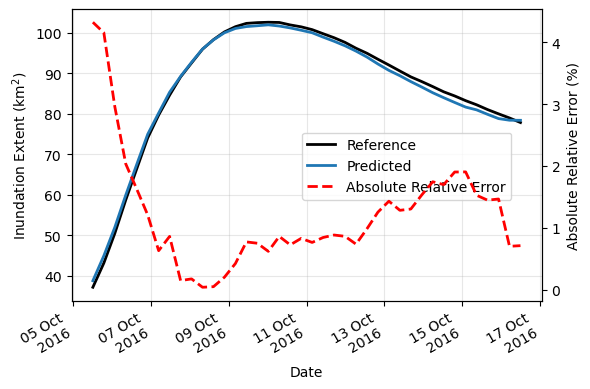

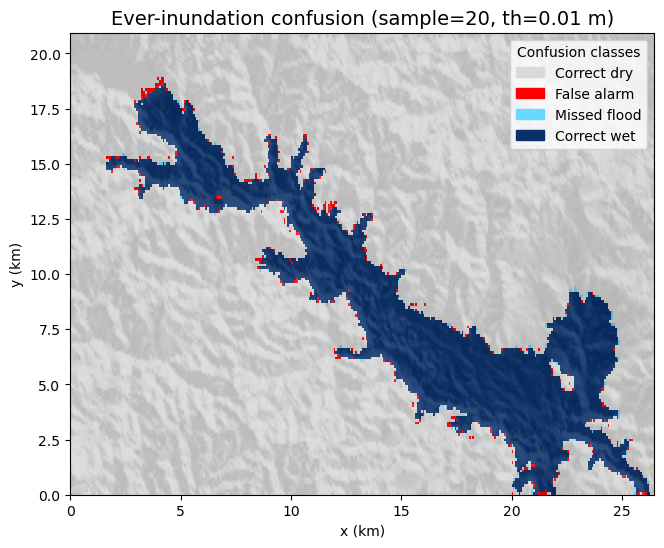

In [29]:
Lx=checkpoint_mag['config_arg']['data_mask']['L_x']
Ly=checkpoint_mag['config_arg']['data_mask']['L_y']
extent = [0, Lx, 0, Ly]

# plot_ever_inundation_confusion(u_true_all, u_upscaled_final, sample_idx=None, inund_th=0.025, extent=extent)
fig, ax = plot_ever_inundation_confusion(
    u_true=u_true_all, 
    u_pred=u_upscaled_final,
    bed=bed_topo_all,              # <-- pass your bed tensor here
    sample_idx=20,
    inund_th=0.01,
    extent=extent,
    hill_vert_exag=3.0,            # tweak for stronger relief
    overlay_alpha=0.85
)


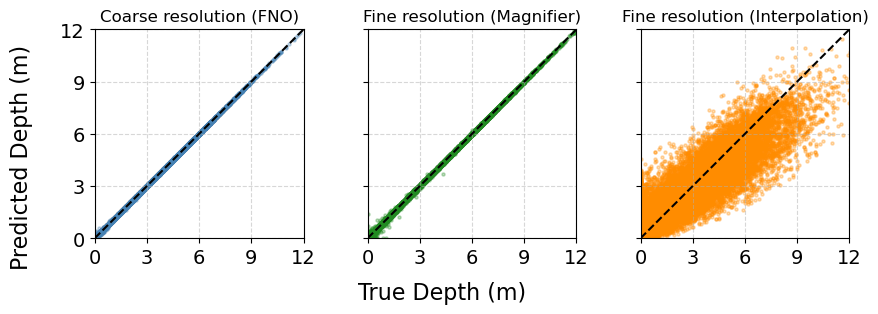

In [30]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ─── Data Setup ─────────────────────────────────────────────────────────────

# Coarse
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# Interpolation baseline (Fine)
u_pred_interp = F.interpolate(
    u_pred_coarse_all.permute(0, 3, 1, 2),   # [B, T, mx, my]
    size=(nx_fine, ny_fine),
    mode='bicubic',
    align_corners=False
).permute(0, 2, 3, 1)                         # [B, H, W, T]
u_pred_interp = torch.clamp(u_pred_interp, min=0.0).detach().cpu().numpy()

# Magnifier (Fine)
u_true_f = u_true_all.detach().cpu().numpy()
u_pred_f = u_upscaled_final.detach().cpu().numpy()

# ─── Helper: Collect Scatter Points ─────────────────────────────────────────

def collect_scatter(u_true, u_pred, max_points_per_sample=5000):
    xs, ys = [], []
    for i in range(u_true.shape[0]):
        x = u_true[i].ravel()
        y = u_pred[i].ravel()

        if x.size > max_points_per_sample:
            idx = np.random.choice(x.size, max_points_per_sample, replace=False)
            x = x[idx]
            y = y[idx]

        xs.append(x)
        ys.append(y)

    return np.concatenate(xs), np.concatenate(ys)

# Build scatter sets
x_c, y_c = collect_scatter(u_true_c, u_pred_c)
x_i, y_i = collect_scatter(u_true_f, u_pred_interp)
x_m, y_m = collect_scatter(u_true_f, u_pred_f)

# Shared limits (use fine domain, since it contains the full range)
limit = 12 #max(x_m.max(), y_m.max(), x_i.max(), y_i.max(), x_c.max(), y_c.max())

# ─── Plot: 1 row × 3 cols ───────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharex=True, sharey=True)

panels = [
    (axes[0], x_c, y_c, "Coarse resolution (FNO)", "steelblue"),
    (axes[1], x_m, y_m, "Fine resolution (Magnifier)", "forestgreen"),
    (axes[2], x_i, y_i, "Fine resolution (Interpolation)", "darkorange"),

]


num_ticks = 5  # change if you want more/less ticks
ticks = np.linspace(0, limit, num_ticks)


for ax, x, y, title, color in panels:
    ax.scatter(x, y, s=5, alpha=0.3, color=color, rasterized=True)
    ax.plot([0, limit], [0, limit], 'k--', lw=1.5)
    ax.set_title(title)

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)

    ax.set_xticks(ticks)
    ax.set_yticks(ticks)


    ax.set_aspect('equal', 'box')
    
    # Make y-axis use the same tick locator as x-axis
    ax.yaxis.set_major_locator(ax.xaxis.get_major_locator())

    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='both', labelsize=14)

# Shared labels
fig.supxlabel("True Depth (m)", fontsize=16)
fig.supylabel("Predicted Depth (m)", fontsize=16)

plt.tight_layout()
plt.savefig('../../../paper/figs/scatter_error_dam_break.png', dpi=600, bbox_inches='tight')

plt.show()


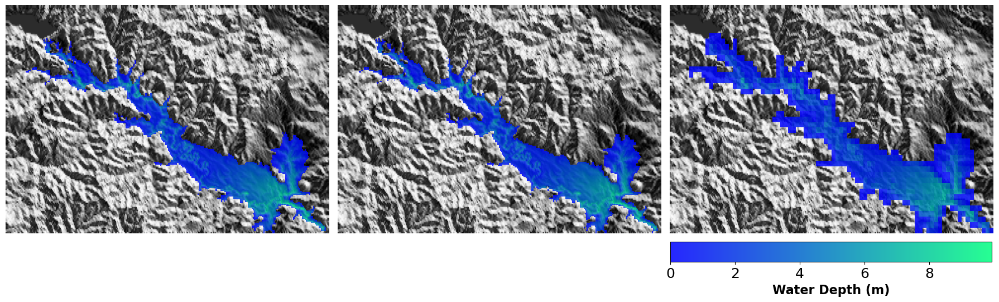

Time: 17:52  |  Frame: 35/47


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from datetime import datetime, timedelta

# ---------------------------
# USER CHOICES
# ---------------------------
sample_idx = 20
time_step  = 35  # <-- frame index you want (0 ... num_frames-1)
extent = [0, 46890.0/1000, 0, 23600.0/1000]

# ---------------------------
# TIME RANGE (NO DATE)
# start = 00:00 , end = 24:00
# ---------------------------
start_seconds = 0               # 00:00
end_seconds   = 24 * 3600       # 24:00

# ==========================================
# 4) Hillshade bed background
# ==========================================
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# ==========================================
# Data
# ==========================================
u_true_c = u_true_all_coarse[sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[sample_idx].detach().cpu().numpy()

u_true_f = u_true_all[sample_idx].detach().cpu().numpy()
u_pred_f = u_upscaled_final[sample_idx].detach().cpu().numpy()

num_frames = u_true_f.shape[-1]

# ==========================================
# Time vector: 00:00 -> 24:00 (no dates)
# ==========================================
time_step = int(np.clip(time_step, 0, num_frames - 1))

total_seconds = (end_seconds - start_seconds)
dt_seconds = total_seconds / (num_frames - 1)

current_seconds = start_seconds + time_step * dt_seconds
hh = int(current_seconds // 3600)
mm = int((current_seconds % 3600) // 60)
time_str = f"{hh:02d}:{mm:02d}"

# --- Match your reference styling ---
min_depth_threshold = 0.025
cmp = "winter"
bed_cmap = "gist_yarg"

global_max_depth = 0.8 * max(u_true_f.max(), u_pred_f.max())
vmin, vmax = 0.0, global_max_depth

def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# Hillshade
# ==========================================
Z = bed_sample
dx = 1.0
dy = 1.0
ls = LightSource(azdeg=315, altdeg=45)
hill = ls.hillshade(Z, vert_exag=2.5, dx=dx, dy=dy)

# ==========================================
# Static Figure: 1 Row x 3 Cols
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# ---- Data at selected time ----
coarse_pred = u_pred_c[:, :, time_step]
fine_true   = u_true_f[:, :, time_step]
fine_pred   = u_pred_f[:, :, time_step]

ims = []
for c in range(3):
    ax = axes[c]

    # panel mapping: 0=True fine, 1=pred fine, 2=pred coarse
    if c == 0:
        panel = fine_true
        interp = None
    elif c == 1:
        panel = fine_pred
        interp = None
    else:
        panel = coarse_pred
        interp = "nearest"

    # Bed background
    ax.imshow(
        hill.T, extent=extent, origin="lower",
        cmap=bed_cmap, vmin=0, vmax=1,
        alpha=1.0, zorder=1
    )

    # Water overlay
    im = ax.imshow(
        mask_dry(panel).T, extent=extent, origin="lower",
        cmap=cmp, vmin=vmin, vmax=vmax,
        alpha=0.85, zorder=2,
        interpolation=interp
    )
    ims.append(im)

    ax.set_axis_off()
    ax.set_aspect(1.4)

# --- Horizontal colorbar at bottom ---
cbar_ax = fig.add_axes([0.67, 0.075, 0.32, 0.06])  # [left, bottom, width, height]
cbar = fig.colorbar(ims[-1], cax=cbar_ax, orientation="horizontal")
cbar.set_label("Water Depth (m)", fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=18)

plt.tight_layout()

# Save using ONLY HH_MM (no date)
plt.savefig(f"../../../paper/figs/2d_depth_{time_str.replace(':','_')}_dam_break_V.png",
            dpi=600, bbox_inches='tight')

plt.show()

print(f"Time: {time_str}  |  Frame: {time_step}/{num_frames-1}")


In [32]:
metrics_fine_interp = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=torch.Tensor(u_pred_interp),
    wet_threshold=0.025,
    peak_percent=0.025
)


In [33]:
metrics_fine_interp['static']

{'relRMSE_mean': 1.055736780166626,
 'relRMSE_std': 0.16314783692359924,
 'NSE_mean': 0.908033013343811,
 'NSE_std': 0.015614631585776806,
 'relRMSE_shallow_mean': 44.91419982910156,
 'relRMSE_shallow_std': 3.2848613262176514,
 'NSE_shallow_mean': -24.51906967163086,
 'NSE_shallow_std': 3.5817623138427734,
 'relRMSE_deep_mean': 0.29887065291404724,
 'relRMSE_deep_std': 0.027544278651475906,
 'NSE_deep_mean': 0.7361192107200623,
 'NSE_deep_std': 0.04579036682844162,
 'POD_mean': 0.9928367733955383,
 'POD_std': 0.001096805790439248,
 'FAR_mean': 0.2438436895608902,
 'FAR_std': 0.010250890627503395,
 'CSI_mean': 0.752055823802948,
 'CSI_std': 0.010287543758749962,
 'relPeakValErr_mean': 0.0129231046885252,
 'relPeakValErr_std': 0.001616619061678648,
 'relPeakTimeErr1_mean': -20000000000.0,
 'relPeakTimeErr1_std': 141421363200.0,
 'relPeakTimeErr2_mean': -0.0010000000474974513,
 'relPeakTimeErr2_std': 0.0070710680447518826}

{'relRMSE_mean': 1.0556203126907349,
 'relRMSE_std': 0.16314299404621124,
 'NSE_mean': 0.9080533385276794,
 'NSE_std': 0.01561350654810667,
 'relRMSE_shallow_mean': 44.92380905151367,
 'relRMSE_shallow_std': 3.284719944000244,
 'NSE_shallow_mean': -24.530052185058594,
 'NSE_shallow_std': 3.5832481384277344,
 'relRMSE_deep_mean': 0.2988114655017853,
 'relRMSE_deep_std': 0.0275445394217968,
 'NSE_deep_mean': 0.7362229824066162,
 'NSE_deep_std': 0.04578297212719917,
 'POD_mean': 0.9928112626075745,
 'POD_std': 0.0010970969451591372,
 'FAR_mean': 0.2436976283788681,
 'FAR_std': 0.010250268504023552,
 'CSI_mean': 0.7521857619285583,
 'CSI_std': 0.010284686461091042,
 'relPeakValErr_mean': 0.013129029422998428,
 'relPeakValErr_std': 0.001572178676724434,
 'relPeakTimeErr1_mean': -20000000000.0,
 'relPeakTimeErr1_std': 141421363200.0,
 'relPeakTimeErr2_mean': -0.0010000000474974513,
 'relPeakTimeErr2_std': 0.0070710680447518826}

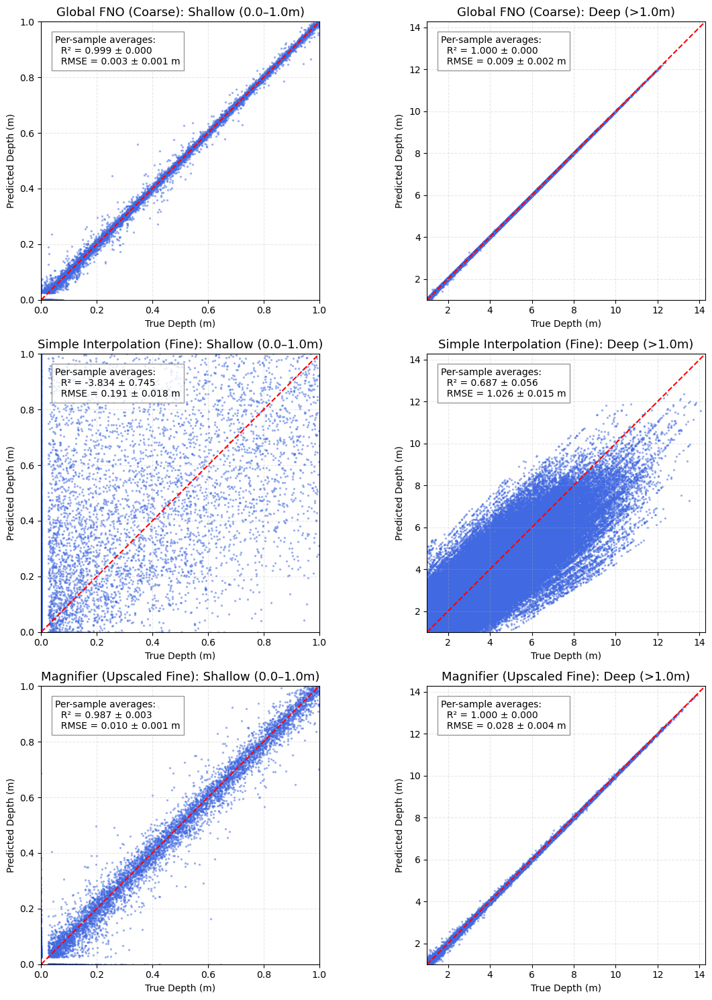

In [34]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# ─── Data Setup ─────────────────────────────────────────────────────────────
# Row 1: Coarse FNO Data
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# 
u_pred_interp = F.interpolate(
    u_pred_coarse_all.permute(0, 3, 1, 2), # [Batch, T, mx, my]
    size=(nx_fine, ny_fine), 
    mode='bicubic', # Standard SR baseline [cite: 37, 107]
    align_corners=False
).permute(0, 2, 3, 1)

# Critical step: Interpolation can create artifacts or negative depths
u_pred_interp = torch.clamp(u_pred_interp, min=0.0).detach().cpu().numpy()

# Row 3: Magnifier (Neural Upscaling)
u_true_f = u_true_all.detach().cpu().numpy()
u_pred_f = u_upscaled_final.detach().cpu().numpy()

# Note: Both Interpolation and Magnifier are compared against the Fine Ground Truth (u_true_f)
datasets = [
    (u_true_c, u_pred_c, "Global FNO (Coarse)"),
    (u_true_f, u_pred_interp, "Simple Interpolation (Fine)"),
    (u_true_f, u_pred_f, "Magnifier (Upscaled Fine)")
]

# Define depth ranges (m)
depth_ranges = [
    (0.0, 1.0, "Shallow (0.0–1.0m)"),
    (1.0, max(u_true_f.max(), u_pred_f.max()), "Deep (>1.0m)")
]

# 3 rows x 2 cols
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for row_idx, (u_true, u_pred, model_name) in enumerate(datasets):
    for col_idx, (dmin, dmax, range_title) in enumerate(depth_ranges):
        ax = axes[row_idx, col_idx]
        
        r2_list, rmse_list = [], []
        scatter_x, scatter_y = [], []
        
        for i in range(u_true.shape[0]):
            true_flat = u_true[i].ravel()
            pred_flat = u_pred[i].ravel()
            
            mask = (true_flat >= dmin) & (true_flat < dmax)
            if np.sum(mask) < 50: continue
                
            x_s, y_s = true_flat[mask], pred_flat[mask]
            
            r2_list.append(r2_score(x_s, y_s))
            rmse_list.append(np.sqrt(mean_squared_error(x_s, y_s)))
            
            if len(x_s) > 5000:
                sel = np.random.choice(len(x_s), 5000, replace=False)
                scatter_x.extend(x_s[sel]); scatter_y.extend(y_s[sel])
            else:
                scatter_x.extend(x_s); scatter_y.extend(y_s)
        
        ax.scatter(scatter_x, scatter_y, s=2, alpha=0.4, color='royalblue', rasterized=True)
        limit_max = dmax if np.isfinite(dmax) else max(scatter_x)
        ax.plot([dmin, limit_max], [dmin, limit_max], 'r--', lw=1.5, label='Ideal')
        
        ax.set_xlim(dmin, limit_max); ax.set_ylim(dmin, limit_max)
        ax.set_aspect('equal')
        
        metrics_text = (
            f"Per-sample averages:\n"
            f"  R² = {np.mean(r2_list):.3f} ± {np.std(r2_list):.3f}\n"
            f"  RMSE = {np.mean(rmse_list):.3f} ± {np.std(rmse_list):.3f} m"
        )
        ax.text(0.05, 0.95, metrics_text, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))
        
        ax.set_title(f"{model_name}: {range_title}", fontsize=13)
        ax.set_xlabel("True Depth (m)"); ax.set_ylabel("Predicted Depth (m)")
        ax.grid(True, ls='--', alpha=0.3)

plt.tight_layout()
plt.show()

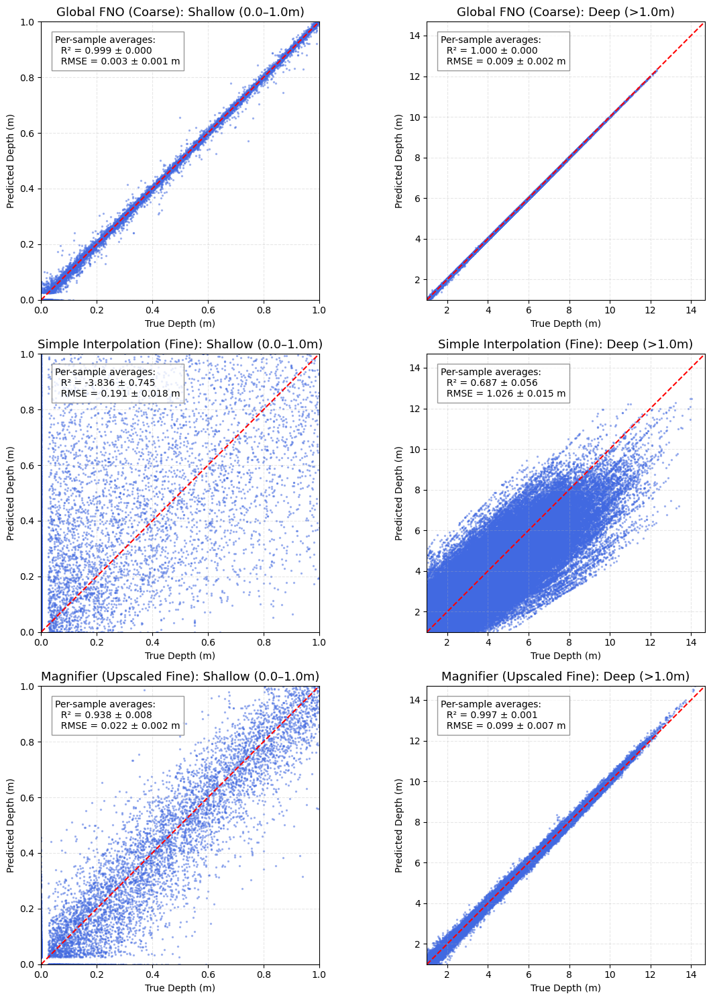

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import LightSource
from IPython.display import HTML

import torch
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
from datetime import datetime, timedelta
import numpy as np

# ==========================================
# 1) Data Selection & Error Calculation
# ==========================================

sample_idx = 20 

# Row 1: Coarse Data [nx_c, ny_c, nt]
u_true_c = u_true_all_coarse[..., ::4][sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[..., ::4][sample_idx].detach().cpu().numpy()
u_err_c  = np.abs(u_true_c - u_pred_c)

# Row 2: Upscaled Data [nx_f, ny_f, nt]
u_true_f = u_true_all[..., ::4][sample_idx].detach().cpu().numpy() 
u_pred_f = u_upscaled_final[..., ::4][sample_idx].detach().cpu().numpy()
u_err_f  = np.abs(u_true_f - u_pred_f)

num_frames = u_true_f.shape[-1]

# ==========================================
# 2) Coordinate & Color Configuration
# ==========================================
start_date = datetime(2016, 10, 5, 12, 0, 0)
time_step_seconds = 3600
time_dates = [start_date + timedelta(seconds=i * time_step_seconds) for i in range(num_frames)]

vmin, vmax = 0.0, max(u_true_f.max(), u_pred_f.max()) * 0.8
err_vmin, err_vmax = 0.0, 0.2  # Fixed scale for error comparison

# Explicitly define the extent to align spatial indices with physical map
X_range = 248417.934 - 201527.934
Y_range = 3922540.192 - 3898940.192
extent = [0, X_range, 0, Y_range]

# ==========================================
# 3) Figure Setup: 2 Rows x 3 Columns
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)

titles = [
    ["True (Coarse)", "Pred (Coarse)", "Abs Error (Coarse)"],
    ["True (Fine)",   "Pred (Upscaled)", "Abs Error (Fine)"]
]

# Initialize image buffer for animation updates
ims = [[None for _ in range(3)] for _ in range(2)]

for r in range(2):
    # Select data based on resolution row
    t_d = u_true_c if r == 0 else u_true_f
    p_d = u_pred_c if r == 0 else u_pred_f
    e_d = u_err_c  if r == 0 else u_err_f
    
    # .T is required to align [nx, ny] with imshow [y, x]
    ims[r][0] = axes[r, 0].imshow(t_d[:, :, 0].T, extent=extent, origin="lower", cmap="terrain", vmin=vmin, vmax=vmax)
    ims[r][1] = axes[r, 1].imshow(p_d[:, :, 0].T, extent=extent, origin="lower", cmap="terrain", vmin=vmin, vmax=vmax)
    ims[r][2] = axes[r, 2].imshow(e_d[:, :, 0].T, extent=extent, origin="lower", cmap="magma", vmin=err_vmin, vmax=err_vmax)
    
    for c in range(3):
        axes[r, c].set_title(titles[r][c], fontsize=12)
        axes[r, c].grid(True, linestyle="--", alpha=0.3)

# Add colorbars for depth and error
cbar_ax1 = fig.add_axes([0.15, 0.06, 0.35, 0.02])
fig.colorbar(ims[1][0], cax=cbar_ax1, label="Water Depth (m)", orientation="horizontal")

cbar_ax2 = fig.add_axes([0.65, 0.06, 0.20, 0.02])
fig.colorbar(ims[1][2], cax=cbar_ax2, label="Abs Error (m)", orientation="horizontal")

plt.subplots_adjust(bottom=0.15, hspace=0.2, wspace=0.1)

# ==========================================
# 4) Update Function
# ==========================================
def update(f_idx):
    current_dt = time_dates[f_idx]
    fig.suptitle(
        f"Flood Refinement Analysis: Sample {sample_idx}\nTime: {current_dt.strftime('%Y-%m-%d %H:%M')}",
        fontsize=16, fontweight="bold"
    )
    
    # Update Coarse Row
    ims[0][0].set_data(u_true_c[:, :, f_idx].T)
    ims[0][1].set_data(u_pred_c[:, :, f_idx].T)
    ims[0][2].set_data(u_err_c[:, :, f_idx].T)
    
    # Update Fine Row
    ims[1][0].set_data(u_true_f[:, :, f_idx].T)
    ims[1][1].set_data(u_pred_f[:, :, f_idx].T)
    ims[1][2].set_data(u_err_f[:, :, f_idx].T)

    return [item for sublist in ims for item in sublist]

# ==========================================
# 5) Generate Animation
# ==========================================

ani = animation.FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())


# --- Match your reference styling ---
min_depth_threshold = 0.025
cmp = "winter"          # water colormap
bed_cmap = "gist_yarg"       # hillshade is already grayscale; keep "gray"

# Choose water scaling like your reference:
global_max_depth = 0.8 * max(u_true_f.max(), u_pred_f.max())
vmin, vmax = 0.0, global_max_depth
err_vmin, err_vmax = 0.0, 0.2

# Helper: mask "dry" pixels so bed shows through
def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# 0) Build "3D-looking" bed background (hillshade)
# ==========================================
# bed_sample is [nx, ny]
Z = bed_sample

# If you know grid resolution, set dx,dy properly. Otherwise 1.0 is fine visually.
dx = 1.0
dy = 1.0

ls = LightSource(azdeg=315, altdeg=45)     # light direction/elevation (tweakable)
hill = ls.hillshade(Z, vert_exag=2.5, dx=dx, dy=dy)  # vert_exag controls "3D strength"

# hill is in [0,1], shape [nx, ny]
# We'll plot hill.T (like your other layers)

# ==========================================
# Figure Setup: 2 Rows x 3 Columns
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)

titles = [
    ["True (Coarse)", "Pred (Coarse)", "Abs Error (Coarse)"],
    ["True (Fine)",   "Pred (Upscaled)", "Abs Error (Fine)"]
]

ims = [[None for _ in range(3)] for _ in range(2)]
bed_images = []

for r in range(2):
    t_d = u_true_c if r == 0 else u_true_f
    p_d = u_pred_c if r == 0 else u_pred_f
    e_d = u_err_c  if r == 0 else u_err_f

    for c in range(3):
        ax = axes[r, c]

        # 1) Hillshade bed background (3D-looking)
        bed_img = ax.imshow(
            hill.T, extent=extent, origin="lower",
            cmap=bed_cmap, vmin=0, vmax=1,
            alpha=1.0, zorder=1
        )
        bed_images.append(bed_img)

        # 2) Foreground layers
        if c == 0:
            frame0 = t_d[:, :, 0]
            ims[r][c] = ax.imshow(
                mask_dry(frame0).T, extent=extent, origin="lower",
                cmap=cmp, vmin=vmin, vmax=vmax,
                alpha=0.85, zorder=2
            )
        elif c == 1:
            frame0 = p_d[:, :, 0]
            ims[r][c] = ax.imshow(
                mask_dry(frame0).T, extent=extent, origin="lower",
                cmap=cmp, vmin=vmin, vmax=vmax,
                alpha=0.85, zorder=2
            )
        else:
            frame0 = e_d[:, :, 0]
            ims[r][c] = ax.imshow(
                frame0.T, extent=extent, origin="lower",
                cmap="magma", vmin=err_vmin, vmax=err_vmax,
                alpha=0.7, zorder=2
            )

        ax.set_title(titles[r][c], fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.3)

# Colorbars
cbar_ax1 = fig.add_axes([0.15, 0.06, 0.35, 0.02])
fig.colorbar(ims[1][0], cax=cbar_ax1, label="Water Depth (m)", orientation="horizontal")

cbar_ax2 = fig.add_axes([0.65, 0.06, 0.20, 0.02])
fig.colorbar(ims[1][2], cax=cbar_ax2, label="Abs Error (m)", orientation="horizontal")

plt.subplots_adjust(bottom=0.15, hspace=0.2, wspace=0.1)

# ==========================================
# Update Function
# ==========================================
def update(f_idx):
    current_dt = time_dates[f_idx]
    fig.suptitle(
        f"Flood Refinement Analysis: Sample {sample_idx}\nTime: {current_dt.strftime('%Y-%m-%d %H:%M')}",
        fontsize=16, fontweight="bold"
    )

    # Coarse
    t0 = u_true_c[:, :, f_idx]
    p0 = u_pred_c[:, :, f_idx]
    ims[0][0].set_data(mask_dry(t0).T)
    ims[0][1].set_data(mask_dry(p0).T)
    ims[0][2].set_data(u_err_c[:, :, f_idx].T)

    # Fine
    t1 = u_true_f[:, :, f_idx]
    p1 = u_pred_f[:, :, f_idx]
    ims[1][0].set_data(mask_dry(t1).T)
    ims[1][1].set_data(mask_dry(p1).T)
    ims[1][2].set_data(u_err_f[:, :, f_idx].T)

    return [item for sublist in ims for item in sublist]

ani = animation.FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())
